# TCGA Glioma Classification
Clovers Aderomi Akitoye | Artificial Intelligence as a Medical Device | University of Hull

Glioma is a primary brain tumour that varies significantly in severity depending on its grade. Lower-grade glioma (LGG) grows slowly and carries a better prognosis, while glioblastoma multiforme (GBM) is aggressive, fast-growing, and associated with poor survival outcomes. Distinguishing between the two is a critical clinical decision because it directly determines treatment intensity, urgency of intervention, and patient counselling. Currently, grading relies on a combination of histopathology and molecular testing, which is expensive and not uniformly available across centres.

This notebook builds a binary classification pipeline using the TCGA glioma dataset, which contains clinical features and 20 molecular mutation markers from 861 patients. The aim is to identify the smallest subset of features that can reliably distinguish LGG from GBM, reducing the number of molecular tests required per patient without sacrificing diagnostic accuracy.

## Imports

Every library and function the notebook uses is declared here in one block. Keeping imports consolidated at the top means there are no hidden dependencies buried halfway through the analysis, and anyone reading this can see exactly what tools are in play before any code runs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# feature selection
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, RFE

# model selection and validation
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV)

# models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# pipeline keeps feature selection inside CV folds to prevent leakage
from sklearn.pipeline import Pipeline

# metrics
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_score, recall_score,
                             f1_score)

# model-agnostic feature importance
from sklearn.inspection import permutation_importance

## Environment

Recording the Python and library versions used for this analysis. 

In [2]:
print('=' * 60)
print('ENVIRONMENT')
print('=' * 60)

import sys
import sklearn

print(f'Python: {sys.version}')
print(f'pandas: {pd.__version__}')
print(f'numpy: {np.__version__}')
print(f'scikit-learn: {sklearn.__version__}')
print(f'matplotlib: {plt.matplotlib.__version__}')
print(f'seaborn: {sns.__version__}')

ENVIRONMENT
Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
pandas: 2.2.3
numpy: 2.1.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2


## Load Data

This is the TCGA glioma dataset, 861 patients with 27 columns. The task is called binary classification to predict if a brain tumour is LGG (lower-grade glioma) or GBM (glioblastoma multiforme).

In [3]:
print('=' * 60)
print('LOAD DATA')
print('=' * 60)

df = pd.read_csv('tcga_glioma_2026.csv')

print(f'Total rows: {len(df)}')
print(f'Total columns: {len(df.columns)}')
print()
df.head()

LOAD DATA
Total rows: 861
Total columns: 27



,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,LGG,TCGA-LGG,TCGA-DU-8164,Male,51 years 108 days,"Oligodendroglioma, NOS",white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
1,LGG,TCGA-LGG,TCGA-QH-A6CY,Male,38 years 261 days,Mixed glioma,white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
2,LGG,TCGA-LGG,TCGA-HW-A5KM,Male,35 years 62 days,"Astrocytoma, NOS",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
3,LGG,TCGA-LGG,TCGA-E1-A7YE,Female,32 years 283 days,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,MUTATED,NOT_MUTATED
4,LGG,TCGA-LGG,TCGA-S9-A6WG,Male,31 years 187 days,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED


Checking data types and structure to see what pandas actually loaded. Every column came in as `object` (string), which confirms nothing was automatically parsed as numeric. The Age column is stored as text like "51 years 108 days", so that will need manual conversion before any model can use it.

In [4]:
print('=' * 60)
print('DATA TYPES AND STRUCTURE')
print('=' * 60)

df.info()

DATA TYPES AND STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Grade              861 non-null    object
 1   Project            861 non-null    object
 2   Case_ID            861 non-null    object
 3   Gender             861 non-null    object
 4   Age_at_diagnosis   861 non-null    object
 5   Primary_Diagnosis  861 non-null    object
 6   Race               861 non-null    object
 7   IDH1               861 non-null    object
 8   TP53               861 non-null    object
 9   ATRX               861 non-null    object
 10  PTEN               861 non-null    object
 11  EGFR               861 non-null    object
 12  CIC                861 non-null    object
 13  MUC16              861 non-null    object
 14  PIK3CA             861 non-null    object
 15  NF1                861 non-null    object
 16  PIK3R1             

Running `describe()` for a high-level summary of each column. Since everything is still stored as a string at this point, this returns counts, unique values, and the most frequent entry rather than the usual mean and standard deviation. It is useful for spotting anything unexpected before the cleaning stage begins.

In [5]:
print('=' * 60)
print('DESCRIPTIVE STATISTICS')
print('=' * 60)

df.describe()

DESCRIPTIVE STATISTICS


,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
count,861,861,861,861,861,861,861,861,861,861,...,861,861,861,861,861,861,861,861,861,861
unique,2,2,861,3,837,7,6,2,2,2,...,2,2,2,2,2,2,2,2,2,2
top,LGG,TCGA-LGG,TCGA-DU-8164,Male,--,Glioblastoma,white,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
freq,499,499,1,498,5,359,766,447,507,641,...,814,820,823,832,833,833,834,838,838,839


### Missing Values

Before cleaning anything, I need to know how much data is actually missing and where. This dataset handles missing entries differently from most, so a standard `isnull()` check on its own will not give the full picture.

In [6]:
print('=' * 60)
print('MISSING VALUES')
print('=' * 60)

# this dataset uses "--" to mark missing values instead of NaN
# pandas isnull() only catches actual NaN,so isnull() misses them completely 
# need to check for "--" separately
print('--- NaN count per column ---')
print(df.isnull().sum())

print()

print('--- Hidden missing values ("--") per column ---')
hidden = (df == '--').sum()
print(hidden[hidden > 0])
print()
print(f'Total "--" entries: {(df == "--").sum().sum()}')

MISSING VALUES
--- NaN count per column ---
Grade                0
Project              0
Case_ID              0
Gender               0
Age_at_diagnosis     0
Primary_Diagnosis    0
Race                 0
IDH1                 0
TP53                 0
ATRX                 0
PTEN                 0
EGFR                 0
CIC                  0
MUC16                0
PIK3CA               0
NF1                  0
PIK3R1               0
FUBP1                0
RB1                  0
NOTCH1               0
BCOR                 0
CSMD3                0
SMARCA4              0
GRIN2A               0
IDH2                 0
FAT4                 0
PDGFRA               0
dtype: int64

--- Hidden missing values ("--") per column ---
Gender               4
Age_at_diagnosis     5
Primary_Diagnosis    4
Race                 4
dtype: int64

Total "--" entries: 17


## Class Balance

499 LGG vs 362 GBM. I did not apply SMOTE here. The ratio is not extreme enough to seriously distort 
the decision boundary, and 362 GBM samples is still a decent amount to learn from. 
Applying SMOTE unnecessarily creates synthetic patients that never actually existed. On a clinical dataset, that feels wrong unless the imbalance is genuinely bad.

If this were 80/20 or worse, I would use it. For now, I will keep an eye on GBM recall during evaluation. If it drops, I will revisit this.

The risk with class imbalance is that the model optimises for the majority class (LGG) because getting those right boosts overall accuracy, which can quietly push GBM recall down. At a 58/42 split that effect is small, but it is why sensitivity is tracked separately throughout this analysis rather than relying on accuracy alone.

CLASS BALANCE
Grade
LGG    499
GBM    362
Name: count, dtype: int64



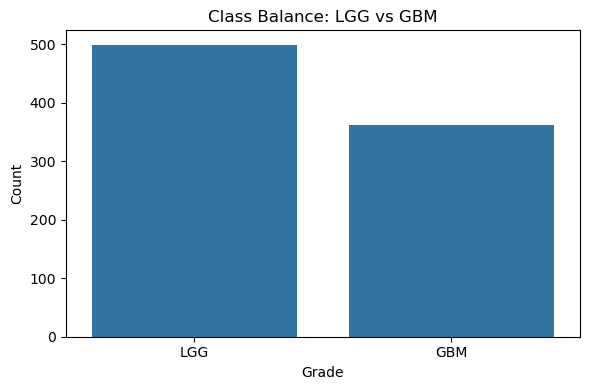

In [7]:
print('=' * 60)
print('CLASS BALANCE')
print('=' * 60)

print(df['Grade'].value_counts())
print()

# visualise
plt.figure(figsize=(6, 4))
sns.countplot(x='Grade', data=df)
plt.title('Class Balance: LGG vs GBM')
plt.xlabel('Grade')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('class_balance.png', dpi=300, bbox_inches='tight')
plt.show()

## Value Counts

Checking every column before I touch anything. I want to know what values exist, what is rare, and what needs cleaning. The "--" entries show up here as actual values because pandas does not recognise them as missing.

In [8]:
print('=' * 60)
print('VALUE COUNTS: ALL COLUMNS')
print('=' * 60)

for col in df.columns:
    print(f'\n--- {col} ---')
    print(df[col].value_counts())

VALUE COUNTS: ALL COLUMNS

--- Grade ---
Grade
LGG    499
GBM    362
Name: count, dtype: int64

--- Project ---
Project
TCGA-LGG    499
TCGA-GBM    362
Name: count, dtype: int64

--- Case_ID ---
Case_ID
TCGA-DU-8164    1
TCGA-19-1786    1
TCGA-28-5219    1
TCGA-14-1455    1
TCGA-41-2575    1
               ..
TCGA-FG-6689    1
TCGA-HT-8013    1
TCGA-HT-A616    1
TCGA-DU-7008    1
TCGA-32-2491    1
Name: count, Length: 861, dtype: int64

--- Gender ---
Gender
Male      498
Female    359
--          4
Name: count, dtype: int64

--- Age_at_diagnosis ---
Age_at_diagnosis
--                   5
64 years 298 days    3
53 years 252 days    2
50 years 232 days    2
58 years 157 days    2
                    ..
36 years 73 days     1
41 years 314 days    1
57 years 201 days    1
52 years 243 days    1
63 years 121 days    1
Name: count, Length: 837, dtype: int64

--- Primary_Diagnosis ---
Primary_Diagnosis
Glioblastoma                     359
Astrocytoma, anaplastic          129
Mixed glioma   

## Data Cleaning

The Age column is stored as a string like "51 years 108 days" which no model can work with, so that needs converting to a decimal number. There are also "--" entries scattered across Gender, Race, Age, and Primary_Diagnosis that are actually missing values, but pandas does not recognise them as such because they are strings. Once those are converted to proper NaN, I can fill them.

In [9]:
print('=' * 60)
print('FIX AGE_AT_DIAGNOSIS')
print('=' * 60)

# Age looks like "51 years 108 days" or just "87 years" or "--"
# converting to decimal years so models can actually use it
# e.g. "51 years 108 days" becomes 51 + (108/365) = 51.3

def parse_age(val):
    if val == '--':
        return np.nan
    # pull out the numbers from the string
    years = 0
    days = 0
    if 'years' in val:
        years = int(val.split('years')[0].strip())
    if 'days' in val:
        days = int(val.split('days')[0].split()[-1].strip())
    return round(years + days / 365, 2)

df['Age_at_diagnosis'] = df['Age_at_diagnosis'].apply(parse_age)

print('After parsing:')
print(df['Age_at_diagnosis'].describe())
print()
print(f'NaN count: {df["Age_at_diagnosis"].isnull().sum()}')

FIX AGE_AT_DIAGNOSIS
After parsing:
count    856.000000
mean      50.894474
std       15.717377
min       14.420000
25%       37.960000
50%       51.510000
75%       62.672500
max       89.290000
Name: Age_at_diagnosis, dtype: float64

NaN count: 5


The `"--"` entries are still sitting in Gender, Race, and Primary_Diagnosis as regular strings. Pandas cannot impute or count values it does not recognise as missing, so this step converts them before any filling happens.

In [10]:
print('=' * 60)
print('REPLACE "--" WITH NaN')
print('=' * 60)

# now that Age is parsed, convert all remaining "--" to proper NaN
# so pandas fillna() and isnull() actually work on them
df.replace('--', np.nan, inplace=True)

print('Missing values after replacement:')
print(df.isnull().sum()[df.isnull().sum() > 0])

REPLACE "--" WITH NaN
Missing values after replacement:
Gender               4
Age_at_diagnosis     5
Primary_Diagnosis    4
Race                 4
dtype: int64


Now that all missing values are properly flagged as NaN, I can fill them. The approach here is straightforward since there are only a handful of gaps and no clinical justification for anything more complex.

In [11]:
print('=' * 60)
print('FILL MISSING VALUES')
print('=' * 60)

# median for age because a few very old patients would pull the mean up
median_age = df['Age_at_diagnosis'].median()
df['Age_at_diagnosis'] = df['Age_at_diagnosis'].fillna(median_age)
print(f'Age filled with median: {median_age}')

# mode for categorical columns. most common value is the safest guess
for col in ['Gender', 'Race', 'Primary_Diagnosis']:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f'{col} filled with mode: {mode_val}')

print()
print('Missing values remaining:')
print(df.isnull().sum().sum())

FILL MISSING VALUES
Age filled with median: 51.51
Gender filled with mode: Male
Race filled with mode: white
Primary_Diagnosis filled with mode: Glioblastoma

Missing values remaining:
0


## Exploratory Data Analysis

Now that the data is clean, I want to understand how the features relate to the grade label before building any models. Age distribution by grade should show whether GBM and LGG patients tend to be different ages. Gender and race breakdowns will tell me if there is any demographic skew. And the mutation frequency chart is the key one because it shows which genes behave differently between LGG and GBM, which is exactly what the model will need to learn.

AGE DISTRIBUTION
count    861.000000
mean      50.898049
std       15.671690
min       14.420000
25%       38.040000
50%       51.510000
75%       62.610000
max       89.290000
Name: Age_at_diagnosis, dtype: float64



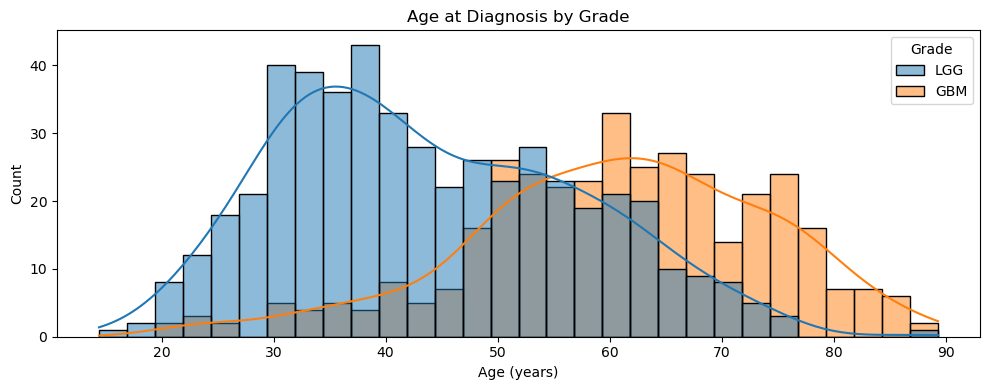

In [12]:
print('=' * 60)
print('AGE DISTRIBUTION')
print('=' * 60)

print(df['Age_at_diagnosis'].describe())
print()

plt.figure(figsize=(10, 4))
sns.histplot(data=df, x='Age_at_diagnosis', hue='Grade', bins=30, kde=True)
plt.title('Age at Diagnosis by Grade')
plt.xlabel('Age (years)')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Breaking down Gender and Race by tumour grade to check for demographic patterns. If one gender or racial group is heavily skewed towards GBM, the model could learn to use demographics as a shortcut instead of learning from the molecular features. I want to confirm that the demographic distribution is reasonably balanced across both grades before proceeding.

GENDER AND RACE BY GRADE


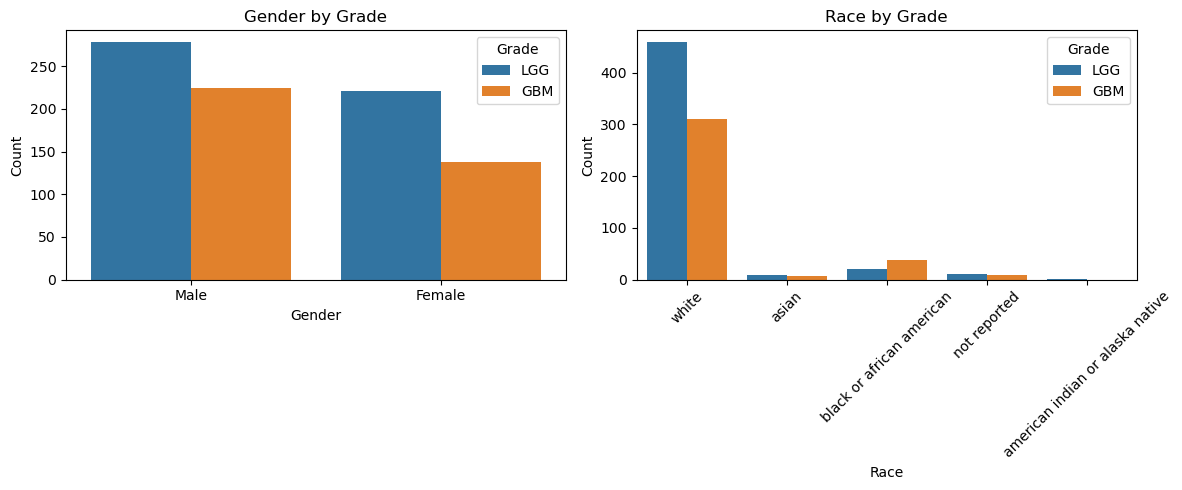

In [13]:
print('=' * 60)
print('GENDER AND RACE BY GRADE')
print('=' * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x='Gender', hue='Grade', data=df, ax=axes[0])
axes[0].set_title('Gender by Grade')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')

sns.countplot(x='Race', hue='Grade', data=df, ax=axes[1])
axes[1].set_title('Race by Grade')
axes[1].set_xlabel('Race')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('gender_race_by_grade.png', dpi=300, bbox_inches='tight')
plt.show()

### Mutation Frequency by Grade

This shows which genes mutate at different rates in LGG versus GBM. A large difference between the two bars for a given gene means that mutation carries useful information for grading. Genes where the LGG and GBM bars are roughly the same height will not help the model distinguish between the two grades, and keeping them in just adds noise without adding signal.

MUTATION FREQUENCY BY GRADE


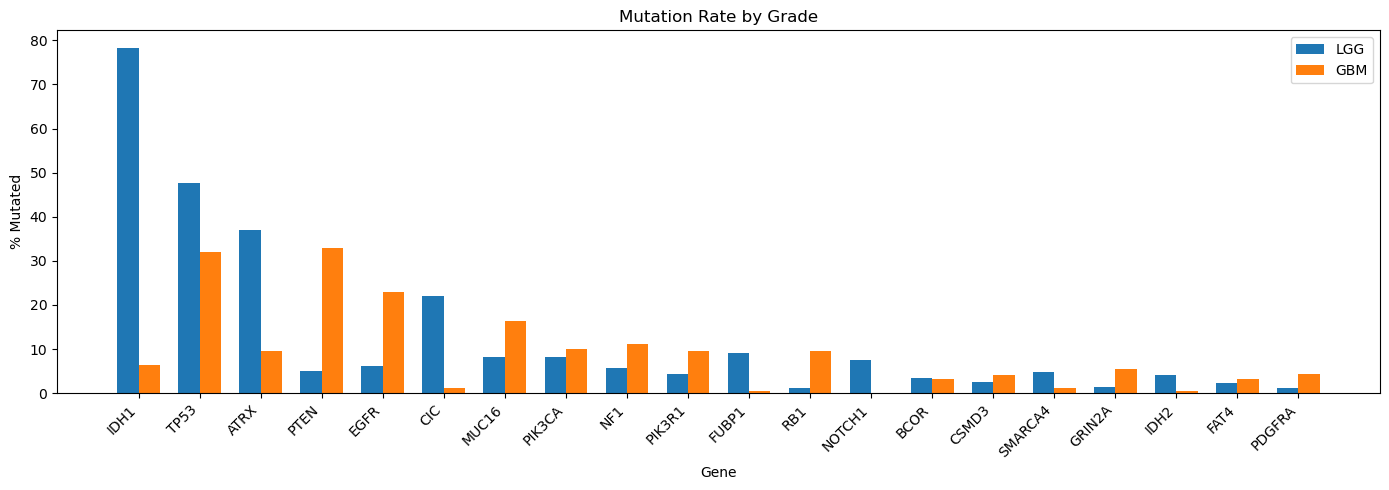

In [14]:
print('=' * 60)
print('MUTATION FREQUENCY BY GRADE')
print('=' * 60)

mutation_cols = ['IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16',
                 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1',
                 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA']

# count mutation rate per gene per grade
lgg = df[df['Grade'] == 'LGG']
gbm = df[df['Grade'] == 'GBM']

# use lgg[col] and gbm[col] so each rate is calculated within its own group
lgg_rates = [(lgg[col] == 'MUTATED').sum() / len(lgg) * 100 for col in mutation_cols]
gbm_rates = [(gbm[col] == 'MUTATED').sum() / len(gbm) * 100 for col in mutation_cols]

x = np.arange(len(mutation_cols))
width = 0.35

plt.figure(figsize=(14, 5))
plt.bar(x - width/2, lgg_rates, width, label='LGG')
plt.bar(x + width/2, gbm_rates, width, label='GBM')
plt.xticks(x, mutation_cols, rotation=45, ha='right')
plt.xlabel('Gene')
plt.ylabel('% Mutated')
plt.title('Mutation Rate by Grade')
plt.legend()
plt.tight_layout()
plt.savefig('mutation_by_grade.png', dpi=300, bbox_inches='tight')
plt.show()

## Feature Encoding

Case_ID and Project were excluded from the feature set. Case_ID is a patient identifier with no predictive value, and Project is the TCGA project code that the sample belongs to. Neither tells the model anything about whether a tumour is LGG or GBM, so including them would introduce noise at best and spurious correlations at worst.

The dataset is entirely strings at this point and no model can work with text values, so every feature needs converting to a numeric representation before modelling. The 20 mutation columns each contain only two values (MUTATED and NOT_MUTATED), which makes LabelEncoder the right choice because it maps binary categories cleanly to 1 and 0 without imposing any false structure. Gender is also binary so the same approach works there, and Age is already numeric after the parsing step.

Primary_Diagnosis was also excluded from the feature set because it contains tumour subtypes like "Glioblastoma" and "Astrocytoma, NOS" that are directly derived from the grade label. Including it would be data leakage, the model would just learn to read the answer from a feature that already contains it.

Race was dropped for two reasons. LabelEncoder would assign its 6 unordered categories numbers from 0 to 5, implying a ranking that does not exist since there is no sense in which one racial category is "greater than" another. On top of that, 89% of patients are white, so the feature carries almost no discriminative signal between LGG and GBM anyway.

In [15]:
print('=' * 60)
print('PRIMARY_DIAGNOSIS vs GRADE')
print('=' * 60)

# showing why Primary_Diagnosis is excluded from features
# if the diagnosis labels map directly to the grade, including it would be data leakage
print(pd.crosstab(df['Primary_Diagnosis'], df['Grade']))

PRIMARY_DIAGNOSIS vs GRADE
Grade                          GBM  LGG
Primary_Diagnosis                      
Astrocytoma, NOS                 0   58
Astrocytoma, anaplastic          0  129
Glioblastoma                   362    1
Mixed glioma                     0  128
Oligodendroglioma, NOS           0  108
Oligodendroglioma, anaplastic    0   75


In [16]:
print('=' * 60)
print('ENCODING')
print('=' * 60)

le = LabelEncoder()

# GBM=1, LGG=0. GBM is the dangerous class so it gets the positive label
grade_map = {'GBM': 1, 'LGG': 0}
df['Grade_encoded'] = df['Grade'].map(grade_map)
print('Grade encoding:', grade_map)

mutation_cols = ['IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16',
                 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1',
                 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA']

# MUTATED=1, NOT_MUTATED=0 for all 20 gene columns
# explicit mapping because LabelEncoder sorts alphabetically and would
# give MUTATED=0 which flips the clinical meaning of every gene
mutation_map = {'MUTATED': 1, 'NOT_MUTATED': 0}
for col in mutation_cols:
    df[col] = df[col].map(mutation_map)
print('Mutation columns encoded.')

# binary column, LabelEncoder is fine here
df['Gender_encoded'] = le.fit_transform(df['Gender'])
print('Gender encoded.')

# Race dropped. false ordinal encoding + 89% white, no useful signal
print('Race dropped. 89% white, LabelEncoder would create false ordering across 6 categories.')

print()
print(df[['Grade', 'Grade_encoded', 'Gender', 'Gender_encoded']].head(3))

ENCODING
Grade encoding: {'GBM': 1, 'LGG': 0}
Mutation columns encoded.
Gender encoded.
Race dropped. 89% white, LabelEncoder would create false ordering across 6 categories.

  Grade  Grade_encoded Gender  Gender_encoded
0   LGG              0   Male               1
1   LGG              0   Male               1
2   LGG              0   Male               1


## Correlation Analysis

Before building any models, I want to see which features actually relate to the target. IDH1 came out strongest at -0.71. The negative sign is what I expected because IDH mutation defines LGG, so when IDH1 is mutated the tumour is almost always LGG (class 0) rather than GBM (class 1).
Age came second at +0.53. GBM tends to affect older patients while LGG is more common in younger adults, so age rising with Grade makes sense.
I am also checking correlation between the features themselves, not just with the target. If two genes always mutate together, one of them is redundant and keeping both just adds noise without adding information. The heatmap below shows whether any features are too tightly coupled.

CORRELATION WITH TARGET
Top 10 features correlated with Grade (positive = GBM, negative = LGG):
IDH1               -0.7114
Age_at_diagnosis    0.5323
PTEN                0.3685
ATRX               -0.3102
CIC                -0.3050
EGFR                0.2435
RB1                 0.1962
FUBP1              -0.1839
NOTCH1             -0.1830
TP53               -0.1570
Name: Grade_encoded, dtype: float64


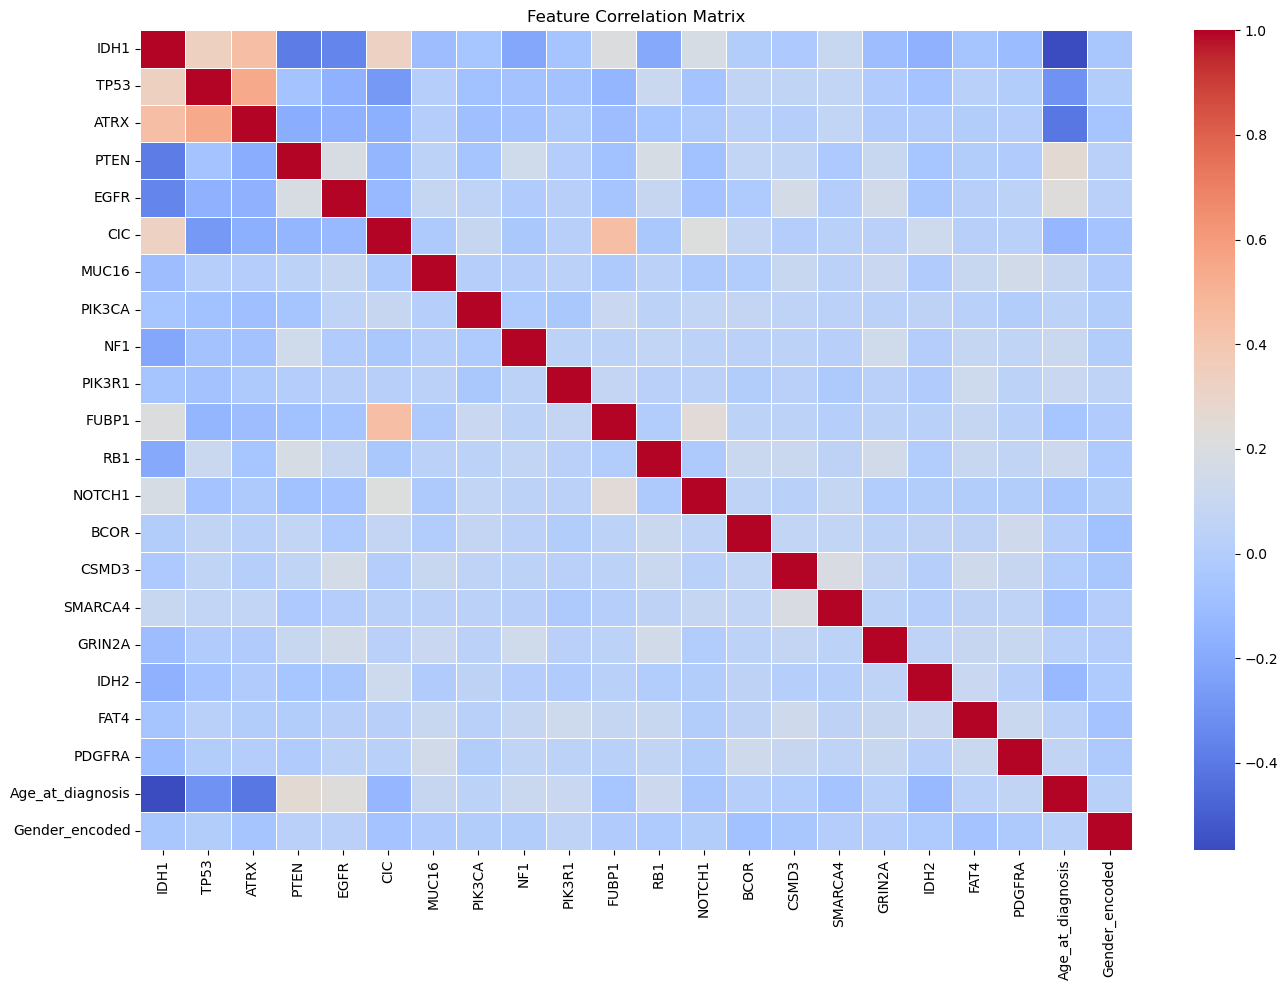

In [17]:
print('=' * 60)
print('CORRELATION WITH TARGET')
print('=' * 60)

# feature set: 20 mutation genes + Age + Gender
feature_cols = mutation_cols + ['Age_at_diagnosis', 'Gender_encoded']

# correlation with Grade, keeping the sign so the direction is visible
# positive = feature points to GBM, negative = feature points to LGG
corr = df[feature_cols + ['Grade_encoded']].corr()['Grade_encoded'].drop('Grade_encoded')

# rank by absolute strength but print the signed value
corr_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)

print('Top 10 features correlated with Grade (positive = GBM, negative = LGG):')
print(corr_sorted.head(10).round(4))

# full correlation matrix to check if any features are too tightly coupled
plt.figure(figsize=(14, 10))
sns.heatmap(df[feature_cols].corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## Feature Selection

22 features is still a lot, and the goal here is to find the smallest subset that actually predicts grade well. In a real clinical setting, fewer features means fewer molecular tests per patient, which means lower cost and faster turnaround. Testing 10 genes costs less than testing 22, so if a smaller panel gets the same performance, that is the better option.

VarianceThreshold removes anything that barely changes across patients, because if a feature is the same for almost everyone then it cannot help distinguish LGG from GBM. Then SelectKBest with chi2 ranks the remaining features by how strongly they associate with the grade label and keeps the top k.

chi2 is a good fit for the mutation features because they are all binary (mutated or not) and the target is also binary (LGG or GBM), which is exactly the kind of relationship chi2 is designed to test. Age_at_diagnosis is continuous rather than categorical, so chi2 is not the ideal statistical test for that one feature. However, Age is non-negative so it runs without error, and with 20 out of 22 features being binary, chi2 is still the most appropriate overall choice for this feature set. An alternative like f_classif (ANOVA F-test) handles mixed feature types more naturally, but the dominant binary features mean the two methods produce very similar rankings here.

In [18]:
print('=' * 60)
print('TRAIN / TEST SPLIT')
print('=' * 60)

X = df[feature_cols]
y = df['Grade_encoded']

# split before any feature selection
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {X_train.shape}')
print(f'Test set: {X_test.shape}')
print(f'Train class balance: {y_train.value_counts().to_dict()}')
print(f'Test class balance: {y_test.value_counts().to_dict()}')

TRAIN / TEST SPLIT
Training set: (688, 22)
Test set: (173, 22)
Train class balance: {0: 399, 1: 289}
Test class balance: {0: 100, 1: 73}


### Variance Threshold

Removing any features with near-zero variance before the main feature selection step. If a gene is almost never mutated or almost always mutated across the dataset, it looks the same in both LGG and GBM patients and therefore cannot help distinguish between them. This is fitted on training data only so the test set remains completely unseen throughout the selection process.

In [19]:
print('=' * 60)
print('FEATURE SELECTION: VARIANCE THRESHOLD')
print('=' * 60)

selector = VarianceThreshold(threshold=0.01)
selector.fit(X_train)

removed = [col for col, keep in zip(feature_cols, selector.get_support()) if not keep]
kept = [col for col, keep in zip(feature_cols, selector.get_support()) if keep]

# apply the filter. any features that did not pass get dropped from both sets
X_train = X_train[kept]
X_test = X_test[kept]

print(f'Features removed (low variance): {removed}')
print(f'Features kept: {len(kept)}')
print(kept)

FEATURE SELECTION: VARIANCE THRESHOLD
Features removed (low variance): []
Features kept: 22
['IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA', 'Age_at_diagnosis', 'Gender_encoded']


### Selecting k for SelectKBest

I need to justify why k=10 and not some other number, so I tested k values from 5 to 15 and checked the cross-validated accuracy for each. SelectKBest is wrapped inside a Pipeline here so it refits on each CV fold, which means there is no leakage from the selector seeing data it should not.

In [20]:
print('=' * 60)
print('SELECTKBEST: K SELECTION')
print('=' * 60)

# Pipeline wraps SelectKBest so it refits on each CV fold
# without this, the selector would see all training data before CV splits it
for k in [5, 8, 10, 12, 15]:
    pipe_k = Pipeline([
        ('selector', SelectKBest(chi2, k=k)),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=42, max_iter=1000))
    ])
    score = cross_val_score(pipe_k, X_train, y_train, cv=5, scoring='accuracy').mean()
    print(f'k={k}: {score:.4f}')

SELECTKBEST: K SELECTION
k=5: 0.8634
k=8: 0.8619
k=10: 0.8663
k=12: 0.8750
k=15: 0.8736


### Applying SelectKBest

Applying SelectKBest with k=10 to the training data. The cross-validated loop above showed that k=12 achieved the highest CV accuracy at 0.8750, with k=10 close behind at 0.8663. The difference is 0.009, which is not clinically meaningful.

k=10 was chosen over k=12 because the goal of this analysis is not just accuracy but also reducing the number of molecular tests required per patient. Each additional gene in the panel adds cost and turnaround time. Dropping two genes for a 0.009 reduction in CV accuracy is a worthwhile tradeoff in a real diagnostic setting. If the performance gap were larger, k=12 would be the correct choice.

The 10 features retained are: IDH1, ATRX, PTEN, EGFR, CIC, MUC16, FUBP1, RB1, NOTCH1, and Age_at_diagnosis.

IDH1 is the strongest predictor, consistent with clinical practice where IDH mutation status is the primary marker for distinguishing LGG from GBM. ATRX and CIC support LGG subtyping, particularly in astrocytomas and oligodendrogliomas respectively. PTEN and EGFR are frequently altered in GBM and add signal in the opposite direction. Age_at_diagnosis is included because GBM disproportionately affects older patients, and it was the second strongest individual correlate with grade after IDH1.

In [21]:
print('=' * 60)
print('FEATURE SELECTION: SELECTKBEST')
print('=' * 60)

# fit on X_train only. never the full dataset
# chi2 tests whether each binary feature is independent of the binary target
# k=12 scored 0.8750 and k=10 scored 0.8663. that is a 0.87% gain for 2 extra genes
# in a clinical panel, each added assay is real cost per patient
# k=10 is the smallest panel that plateaus on performance without paying for marginal gain
skb = SelectKBest(chi2, k=10)
skb.fit(X_train, y_train)

X_train_skb = skb.transform(X_train)
X_test_skb = skb.transform(X_test)

skb_support = skb.get_support()
selected_features = [col for col, keep in zip(kept, skb_support) if keep]

print('Top 10 features selected by chi2:')
print(selected_features)
print()
print(f'X_train after SelectKBest: {X_train_skb.shape}')
print(f'X_test after SelectKBest: {X_test_skb.shape}')

FEATURE SELECTION: SELECTKBEST
Top 10 features selected by chi2:
['IDH1', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'FUBP1', 'RB1', 'NOTCH1', 'Age_at_diagnosis']

X_train after SelectKBest: (688, 10)
X_test after SelectKBest: (173, 10)


## Feature Selection: RFE

While SelectKBest scores features using a statistical test, RFE takes a model-driven approach. It trains a classifier, ranks features by importance, drops the weakest one, and repeats until it reaches the target number. So SelectKBest asks "which features correlate with the target?" while RFE asks "which features actually help a classifier predict better?" Running both and comparing the overlap gives a stronger justification for the final feature set than relying on either method alone.

In [22]:
print('=' * 60)
print('FEATURE SELECTION: RFE')
print('=' * 60)

# logistic regression as the base estimator for RFE
# picking 10 features to match SelectKBest for a fair comparison
rfe = RFE(estimator=LogisticRegression(random_state=42, max_iter=1000), n_features_to_select=10)
rfe.fit(X_train, y_train)

rfe_support = rfe.get_support()
rfe_features = [col for col, keep in zip(kept, rfe_support) if keep]

print('Top 10 features selected by RFE:')
print(rfe_features)
print()

# side by side: which features survived which method
print('--- Feature Selection Comparison ---')
print(f'{"Feature":<25} {"VarianceThreshold":>18} {"SelectKBest":>12} {"RFE":>6}')
print('-' * 65)

for col in kept:
    in_skb = col in selected_features
    in_rfe = col in rfe_features
    print(f'{col:<25} {"yes":>18} {str(in_skb):>12} {str(in_rfe):>6}')

print()
# the overlap tells me which features both methods agree on
overlap = [col for col in selected_features if col in rfe_features]
print(f'Features selected by both SelectKBest and RFE ({len(overlap)}):')
print(overlap)

FEATURE SELECTION: RFE
Top 10 features selected by RFE:
['IDH1', 'TP53', 'PTEN', 'CIC', 'NF1', 'PIK3R1', 'RB1', 'NOTCH1', 'GRIN2A', 'IDH2']

--- Feature Selection Comparison ---
Feature                    VarianceThreshold  SelectKBest    RFE
-----------------------------------------------------------------
IDH1                                     yes         True   True
TP53                                     yes        False   True
ATRX                                     yes         True  False
PTEN                                     yes         True   True
EGFR                                     yes         True  False
CIC                                      yes         True   True
MUC16                                    yes         True  False
PIK3CA                                   yes        False  False
NF1                                      yes        False   True
PIK3R1                                   yes        False   True
FUBP1                                    

### Why I Went With SelectKBest

5 features overlapped between SelectKBest and RFE: IDH1, PTEN, CIC, RB1, and NOTCH1. That is meaningful agreement given the methods measure different things. chi2 looks at statistical association with the label, while RFE looks at what helps a logistic regression model classify better.

The important thing is that IDH1 appears in both, because it is the single most important marker in glioma grading. Both methods agreeing on it is reassuring.

I went with the SelectKBest set because the k-selection loop showed k=10 captures the performance plateau, and the selected features include IDH1, ATRX, PTEN, and EGFR (the four most clinically established glioma markers) plus Age. The RFE comparison serves as a cross-check rather than a replacement.

From a clinical cost perspective, the SelectKBest panel covers the most actionable markers. IDH1 already guides treatment decisions in WHO glioma classification, EGFR and PTEN inform targeted therapy eligibility, and ATRX is used alongside IDH for astrocytoma subtyping. A panel built around these markers slots into existing neuropathology workflows more easily than the RFE-derived panel, which includes genes like GRIN2A and IDH2 that have less established roles in routine clinical grading.

### Feature Scaling

SVM and Logistic Regression are both sensitive to feature scale, so this step is essential for those two models to work properly. Random Forest and Naive Bayes do not technically need it, but running all four models on the same scaled data keeps the comparison fair and avoids introducing an unnecessary variable.

In [23]:
print('=' * 60)
print('SCALING')
print('=' * 60)

# fit on training data only. test set gets transformed with the same parameters
# otherwise the scaler learns the test distribution and that is leakage
scaler = StandardScaler()
scaler.fit(X_train_skb)

X_train_scaled = scaler.transform(X_train_skb)
X_test_scaled = scaler.transform(X_test_skb)

print('Scaling done.')
print(f'X_train_scaled shape: {X_train_scaled.shape}')
print(f'X_test_scaled shape: {X_test_scaled.shape}')

SCALING
Scaling done.
X_train_scaled shape: (688, 10)
X_test_scaled shape: (173, 10)


## Model Training and Evaluation

I am running four models to compare, each with different assumptions about the data. Logistic Regression assumes a linear boundary between classes, which is simple and fast but often surprisingly effective on clean, well-featured data. Random Forest builds many decision trees and averages them, so it handles non-linear patterns better. SVM finds the best separating boundary and works well when features are properly scaled. And Gaussian Naive Bayes assumes all features are independent, which is a bold assumption, but it is fast and easy to interpret.

The metric I care about most here is sensitivity for GBM. A missed GBM means a patient with a deadly tumour gets treated as though they have a slow-growing LGG, and that is a dangerous mistake with serious consequences for the patient. A false positive on the other hand (flagging an LGG as GBM) means extra testing, which is inconvenient but not life-threatening. So the cost of the two error types is not equal, and the model selection needs to reflect that.

MODEL 1: LOGISTIC REGRESSION
Accuracy: 0.8497

              precision    recall  f1-score   support

           0       0.90      0.83      0.86       100
           1       0.79      0.88      0.83        73

    accuracy                           0.85       173
   macro avg       0.85      0.85      0.85       173
weighted avg       0.85      0.85      0.85       173



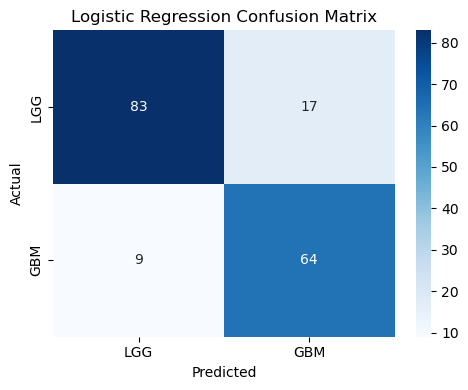

In [24]:
print('=' * 60)
print('MODEL 1: LOGISTIC REGRESSION')
print('=' * 60)

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print(f'Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}')
print()
print(classification_report(y_test, y_pred_lr))

cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG', 'GBM'],
            yticklabels=['LGG', 'GBM'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.savefig('cm_lr.png', dpi=300, bbox_inches='tight')
plt.show()

### Random Forest

Ensemble of decision trees that handles non-linear relationships between features. With 10 binary mutation features plus Age, there could be interaction effects (e.g. EGFR mutation only matters when IDH1 is wild-type) that a single linear model would miss. Running with default hyperparameters here for the baseline comparison, with tuning applied later via GridSearchCV.

MODEL 2: RANDOM FOREST
Accuracy: 0.8208

              precision    recall  f1-score   support

           0       0.84      0.85      0.85       100
           1       0.79      0.78      0.79        73

    accuracy                           0.82       173
   macro avg       0.82      0.82      0.82       173
weighted avg       0.82      0.82      0.82       173



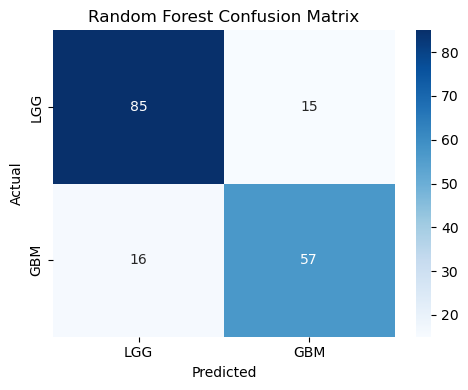

In [25]:
print('=' * 60)
print('MODEL 2: RANDOM FOREST')
print('=' * 60)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

print(f'Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}')
print()
print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG', 'GBM'],
            yticklabels=['LGG', 'GBM'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.savefig('cm_rf.png', dpi=300, bbox_inches='tight')
plt.show()

### SVM

Support Vector Machine with RBF kernel. It finds the optimal separating boundary between classes and works well when features are properly scaled, which they are after the StandardScaler step above. The RBF kernel can capture non-linear boundaries, which matters here because the relationship between mutation combinations and grade is unlikely to be purely linear. `probability=True` is set so that `predict_proba()` is available later for ROC curve plotting and threshold analysis.

MODEL 3: SVM
Accuracy: 0.8324

              precision    recall  f1-score   support

           0       0.89      0.81      0.85       100
           1       0.77      0.86      0.81        73

    accuracy                           0.83       173
   macro avg       0.83      0.84      0.83       173
weighted avg       0.84      0.83      0.83       173



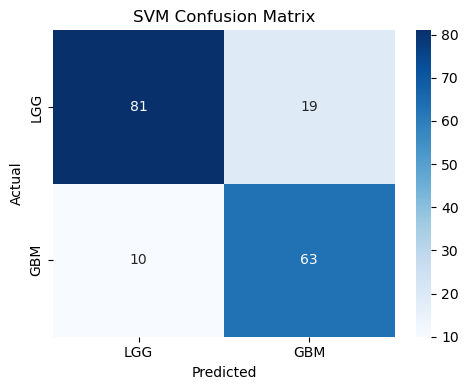

In [26]:
print('=' * 60)
print('MODEL 3: SVM')
print('=' * 60)

svm = SVC(random_state=42, probability=True)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

print(f'Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}')
print()
print(classification_report(y_test, y_pred_svm))

cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG', 'GBM'],
            yticklabels=['LGG', 'GBM'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.tight_layout()
plt.savefig('cm_svm.png', dpi=300, bbox_inches='tight')
plt.show()

### Gaussian Naive Bayes

Assumes all features are independent of each other, which is a strong assumption for genomic data where genes frequently co-mutate (e.g. IDH1 and ATRX in LGG astrocytomas). It is included here as a simple probabilistic baseline. If it performs close to the other models despite the independence assumption, that suggests the selected features carry enough individual signal that co-mutation patterns are not critical for grading. If it performs significantly worse, that confirms interaction effects matter and models like RF or SVM are the better fit.

MODEL 4: GAUSSIAN NAIVE BAYES
Accuracy: 0.6936

              precision    recall  f1-score   support

           0       0.89      0.54      0.67       100
           1       0.59      0.90      0.71        73

    accuracy                           0.69       173
   macro avg       0.74      0.72      0.69       173
weighted avg       0.76      0.69      0.69       173



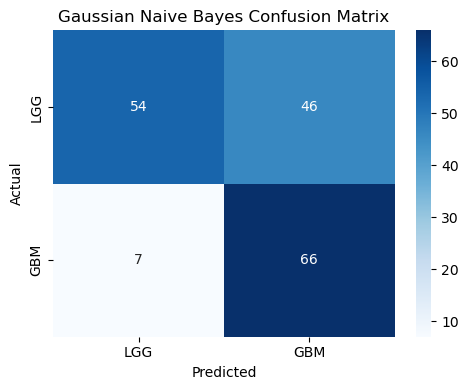

In [27]:
print('=' * 60)
print('MODEL 4: GAUSSIAN NAIVE BAYES')
print('=' * 60)

gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)
y_pred_gnb = gnb.predict(X_test_scaled)

print(f'Accuracy: {accuracy_score(y_test, y_pred_gnb):.4f}')
print()
print(classification_report(y_test, y_pred_gnb))

cm = confusion_matrix(y_test, y_pred_gnb)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG', 'GBM'],
            yticklabels=['LGG', 'GBM'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian Naive Bayes Confusion Matrix')
plt.tight_layout()
plt.savefig('cm_gnb.png', dpi=300, bbox_inches='tight')
plt.show()

## Model Comparison

Four models trained. Now I need to compare them on the metrics that actually matter.

Accuracy alone is not enough here. If both error types were equally bad, accuracy 
would be fine. But missing a GBM is worse than misclassifying an LGG, so sensitivity 
and AUC get priority.

In [28]:
print('=' * 60)
print('MODEL COMPARISON: SENSITIVITY, SPECIFICITY, AUC, F1')
print('=' * 60)

# GBM is class 1, LGG is class 0
# predict_proba[:, 1] gives GBM probability which is what the ROC curve needs
# AUC is symmetric so the score is identical regardless of which class is treated as positive
all_preds = {
    'Logistic Regression': (y_pred_lr, lr.predict_proba(X_test_scaled)[:, 1]),
    'Random Forest':       (y_pred_rf, rf.predict_proba(X_test_scaled)[:, 1]),
    'SVM':                 (y_pred_svm, svm.predict_proba(X_test_scaled)[:, 1]),
    'Gaussian NB':         (y_pred_gnb, gnb.predict_proba(X_test_scaled)[:, 1])
}

summary_rows = []

for name, (preds, probs) in all_preds.items():
    cm = confusion_matrix(y_test, preds)

    # GBM=1, LGG=0 so GBM true positives sit at cm[1][1]
    # GBM is the positive class because it is the dangerous one
    gbm_tp = cm[1][1]  # actual GBM, predicted GBM
    gbm_fn = cm[1][0]  # actual GBM, predicted LGG
    lgg_tp = cm[0][0]  # actual LGG, predicted LGG
    lgg_fn = cm[0][1]  # actual LGG, predicted GBM

    acc = accuracy_score(y_test, preds)
    sensitivity = gbm_tp / (gbm_tp + gbm_fn)  # GBM recall
    specificity = lgg_tp / (lgg_tp + lgg_fn)  # LGG recall
    auc = roc_auc_score(y_test, probs)

    # F1 for GBM. GBM is class 1 now so pos_label defaults correctly
    f1 = f1_score(y_test, preds)

    summary_rows.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Sensitivity': round(sensitivity, 4),
        'Specificity': round(specificity, 4),
        'AUC': round(auc, 4),
        'F1 (GBM)': round(f1, 4)
    })

summary_df = pd.DataFrame(summary_rows).set_index('Model')
print(summary_df)

MODEL COMPARISON: SENSITIVITY, SPECIFICITY, AUC, F1
                     Accuracy  Sensitivity  Specificity     AUC  F1 (GBM)
Model                                                                    
Logistic Regression    0.8497       0.8767         0.83  0.9014    0.8312
Random Forest          0.8208       0.7808         0.85  0.9091    0.7862
SVM                    0.8324       0.8630         0.81  0.8817    0.8129
Gaussian NB            0.6936       0.9041         0.54  0.8753    0.7135


## Model Comparison Chart

The table above is useful but four rows of numbers are hard to compare at a glance, so this chart puts all four metrics side by side to make the tradeoffs between models visible immediately.

MODEL COMPARISON CHART


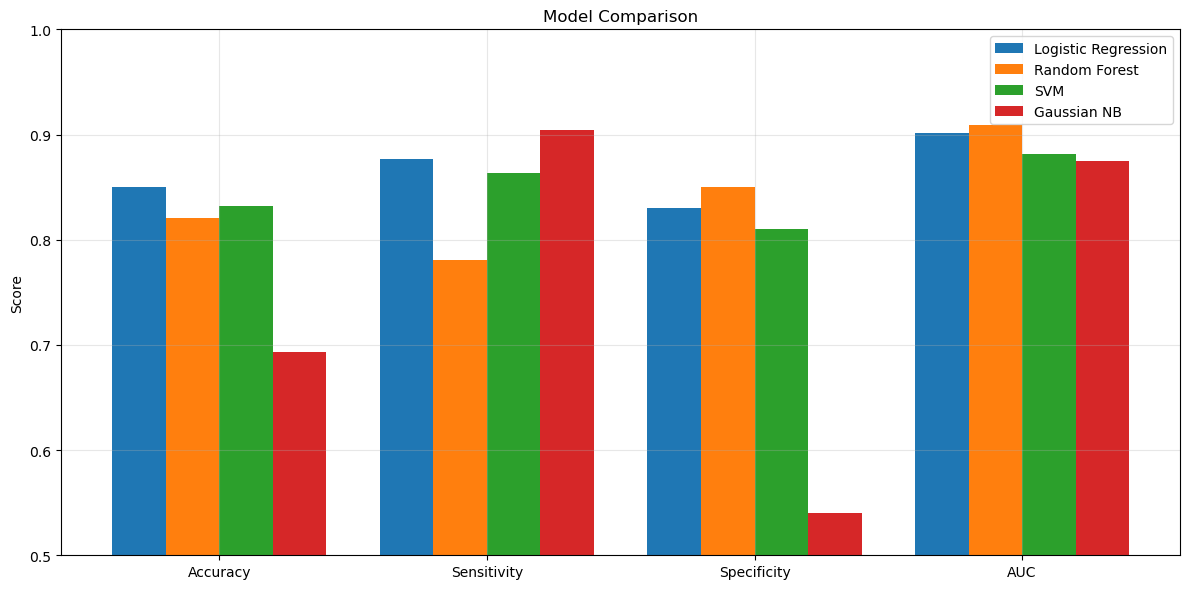

In [29]:
print('=' * 60)
print('MODEL COMPARISON CHART')
print('=' * 60)

# grouped bar chart so the tradeoffs between models are obvious
metrics = ['Accuracy', 'Sensitivity', 'Specificity', 'AUC']
x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))

for i, (model_name, row) in enumerate(summary_df.iterrows()):
    values = [row['Accuracy'], row['Sensitivity'], row['Specificity'], row['AUC']]
    ax.bar(x + i * width, values, width, label=model_name)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_title('Model Comparison')
ax.legend()
ax.set_ylim(0.5, 1.0)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('model_comparison_chart.png', dpi=300, bbox_inches='tight')
plt.show()

### Misclassification Analysis

Looking at the patients the best baseline model (SVM) got wrong. If most missed GBMs share a pattern, that tells us where the model is weakest and what kind of cases would still need human review in a clinical setting.

In [30]:
print('=' * 60)
print('MISCLASSIFICATION ANALYSIS: SVM')
print('=' * 60)

# which GBM patients did SVM miss (predicted LGG but actually GBM)
# GBM is class 1, LGG is class 0
missed_gbm_mask = (y_test == 1) & (y_pred_svm == 0)
caught_gbm_mask = (y_test == 1) & (y_pred_svm == 1)

# reconstruct the test set with feature names for inspection
X_test_named = pd.DataFrame(X_test_skb, columns=selected_features, index=X_test.index)

missed_gbm = X_test_named[missed_gbm_mask]
caught_gbm = X_test_named[caught_gbm_mask]

print(f'GBM cases in test set: {(y_test == 1).sum()}')
print(f'Correctly identified: {caught_gbm_mask.sum()}')
print(f'Missed (predicted LGG): {missed_gbm_mask.sum()}')
print()

# compare missed vs caught on key features
print('--- Age comparison ---')
print(f'Caught GBM mean age: {caught_gbm["Age_at_diagnosis"].mean():.1f}')
print(f'Missed GBM mean age: {missed_gbm["Age_at_diagnosis"].mean():.1f}')
print()

# IDH1 status of missed cases
print('--- IDH1 mutation in missed GBM cases ---')
print(f'Missed GBM with IDH1 mutated: {(missed_gbm["IDH1"] == 1).sum()} / {len(missed_gbm)}')
print(f'Caught GBM with IDH1 mutated: {(caught_gbm["IDH1"] == 1).sum()} / {len(caught_gbm)}')

MISCLASSIFICATION ANALYSIS: SVM
GBM cases in test set: 73
Correctly identified: 63
Missed (predicted LGG): 10

--- Age comparison ---
Caught GBM mean age: 64.3
Missed GBM mean age: 38.0

--- IDH1 mutation in missed GBM cases ---
Missed GBM with IDH1 mutated: 7 / 10
Caught GBM with IDH1 mutated: 0 / 63


10 out of 73 GBM cases were missed. The missed cases were significantly younger (mean age 38.0 vs 64.3 for correctly identified GBMs) and mostly IDH1-mutated (7 out of 10). These patients do not fit the typical GBM profile of older age with IDH wild-type status, nor the typical LGG profile of younger age with IDH mutation. The model leans on the Age and IDH1 combination, so young IDH-mutant GBMs look like LGG to it. In a clinical deployment, low-confidence predictions should be flagged for mandatory pathologist review rather than issuing an automated grade, because these boundary cases are exactly where human expertise is most needed.

### ROC Curves

The ROC curve plots sensitivity against false positive rate at every possible decision threshold. A model that hugs the top-left corner is performing well because it catches most true positives without triggering many false alarms. AUC summarises the entire curve into a single number, where 1.0 is perfect discrimination and 0.5 is no better than random guessing.

ROC CURVES


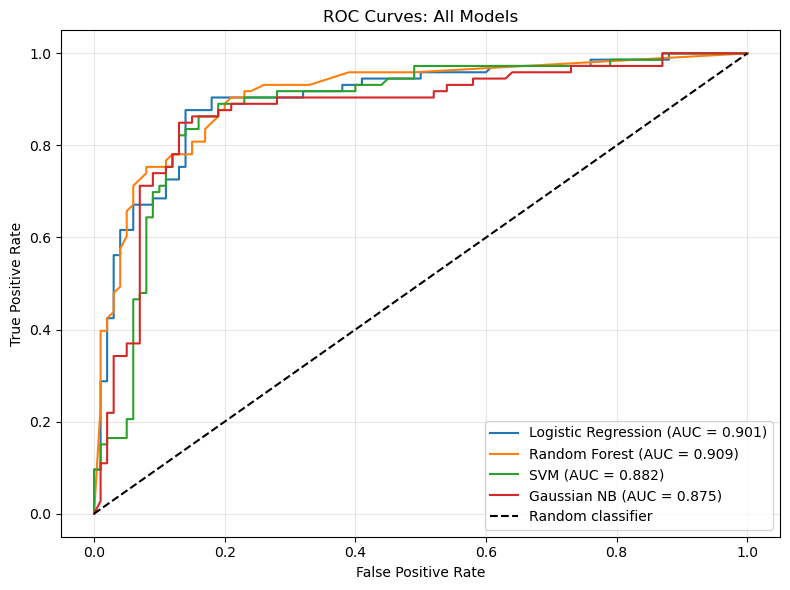

In [31]:
print('=' * 60)
print('ROC CURVES')
print('=' * 60)

plt.figure(figsize=(8, 6))

for name, (preds, probs) in all_preds.items():
    # probs are for GBM (class 1)
# roc_curve treats the higher label as positive by default
# AUC is identical regardless of which class is treated as positive
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: All Models')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## Precision and Recall by Model

Precision tells me how often a GBM prediction was actually correct, and recall tells me how many of the real GBM cases the model managed to catch. Both matter clinically because high recall with low precision means lots of false alarms clogging up the system, while low recall means GBM cases slipping through undetected. The chart below shows where each model sits on that tradeoff.

PRECISION AND RECALL BY MODEL
Model                       GBM Precision   GBM Recall
-------------------------------------------------------
Logistic Regression                0.7901       0.8767
Random Forest                      0.7917       0.7808
SVM                                0.7683       0.8630
Gaussian NB                        0.5893       0.9041


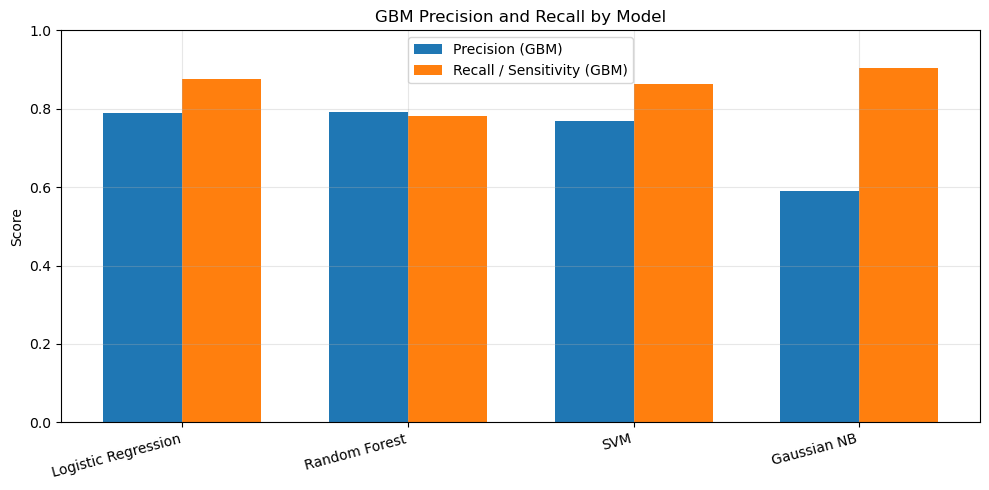

In [32]:
print('=' * 60)
print('PRECISION AND RECALL BY MODEL')
print('=' * 60)

# GBM is class 1, so precision_score and recall_score default to reporting GBM metrics
# no pos_label argument needed

print(f'{"Model":<25} {"GBM Precision":>15} {"GBM Recall":>12}')
print('-' * 55)

gbm_precisions = []
gbm_recalls = []

for name, (preds, probs) in all_preds.items():
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    gbm_precisions.append(prec)
    gbm_recalls.append(rec)
    print(f'{name:<25} {prec:>15.4f} {rec:>12.4f}')

model_names = list(all_preds.keys())
x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, gbm_precisions, width, label='Precision (GBM)')
plt.bar(x + width/2, gbm_recalls, width, label='Recall / Sensitivity (GBM)')
plt.xticks(x, model_names, rotation=15, ha='right')
plt.ylabel('Score')
plt.title('GBM Precision and Recall by Model')
plt.legend()
plt.ylim(0, 1.0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('precision_recall_bar.png', dpi=300, bbox_inches='tight')
plt.show()

### Feature Importance: Random Forest (Baseline)

The built-in `feature_importances_` in Random Forest ranks features by mean decrease in impurity (Gini), which measures how much each feature contributed to splits across all the trees. This gives a quick initial look at what the baseline model is relying on most. A more robust check using permutation importance comes after tuning, since Gini importance can sometimes overrate features that happen to have many possible split points rather than features that genuinely improve prediction.

FEATURE IMPORTANCE: RANDOM FOREST
Age_at_diagnosis    0.472630
IDH1                0.349792
PTEN                0.042065
CIC                 0.036965
ATRX                0.032330
EGFR                0.024266
RB1                 0.014885
MUC16               0.013828
NOTCH1              0.007598
FUBP1               0.005641
dtype: float64


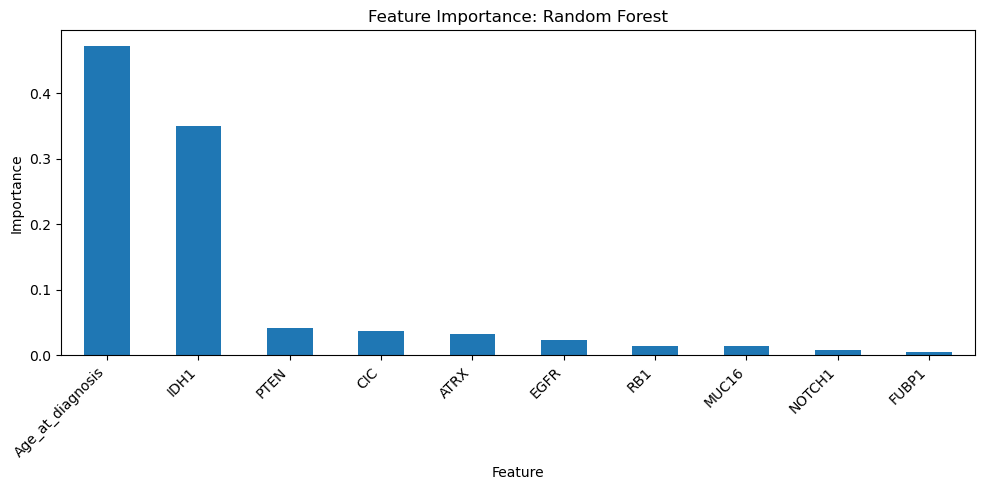

In [33]:
print('=' * 60)
print('FEATURE IMPORTANCE: RANDOM FOREST')
print('=' * 60)

importances = rf.feature_importances_
feat_imp = pd.Series(importances, index=selected_features).sort_values(ascending=False)

print(feat_imp)

plt.figure(figsize=(10, 5))
feat_imp.plot(kind='bar')
plt.title('Feature Importance: Random Forest')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

## Cross-Validation

Test set results depend entirely on which 20% of patients happened to land in the test split, so they could be lucky or unlucky. Cross-validation gives a more honest picture by running the model on 5 different train/test splits and averaging the result, which smooths out the randomness of any single split.

VarianceThreshold was applied to the full training set before this cross-validation loop. This is acceptable because it is unsupervised and only removes near-constant features, so no label information leaks across folds.

In [34]:
print('=' * 60)
print('CROSS-VALIDATION: ALL MODELS')
print('=' * 60)

# SelectKBest is inside the Pipeline so it refits fresh on each fold
# without this, the selector sees validation data during feature selection, which is leakage
cv_models = {
    'Logistic Regression': Pipeline([
        ('selector', SelectKBest(chi2, k=10)),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('selector', SelectKBest(chi2, k=10)),
        ('scaler', StandardScaler()),
        ('clf', RandomForestClassifier(random_state=42))
    ]),
    'SVM': Pipeline([
        ('selector', SelectKBest(chi2, k=10)),
        ('scaler', StandardScaler()),
        ('clf', SVC(random_state=42, probability=True))
    ]),
    'Gaussian NB': Pipeline([
        ('selector', SelectKBest(chi2, k=10)),
        ('scaler', StandardScaler()),
        ('clf', GaussianNB())
    ])
}

# cv=5 uses stratified k-fold by default for classifiers,
# which keeps class proportions consistent across all folds
cv = 5

print(f'{"Model":<25} {"Mean CV Acc":>12} {"Std":>8}')
print('-' * 48)

cv_results = {}
for name, pipeline in cv_models.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = scores.mean()
    print(f'{name:<25} {scores.mean():>12.4f} {scores.std():>8.4f}')

CROSS-VALIDATION: ALL MODELS
Model                      Mean CV Acc      Std
------------------------------------------------
Logistic Regression             0.8663   0.0191
Random Forest                   0.8082   0.0280
SVM                             0.8663   0.0192
Gaussian NB                     0.7195   0.0914


### Generalisation Check

Comparing cross-validated accuracy (the average across 5 folds of training data) against the held-out test set accuracy. If the two scores are close, the model generalises well to data it has not seen during training. A large gap between them would indicate overfitting, where the model has learned the training data too closely and cannot handle new patients reliably.

In [35]:
print('=' * 60)
print('GENERALISATION CHECK: CV vs TEST SCORES')
print('=' * 60)

# if CV accuracy and test accuracy are close, the model generalises well
# big gap would mean overfitting: good on training data, bad on new patients

cv_scores = cv_results

test_scores = {
    'Logistic Regression': accuracy_score(y_test, y_pred_lr),
    'Random Forest': accuracy_score(y_test, y_pred_rf),
    'SVM': accuracy_score(y_test, y_pred_svm),
    'Gaussian NB': accuracy_score(y_test, y_pred_gnb)
}

print(f'{"Model":<25} {"CV Acc":>8} {"Test Acc":>10} {"Gap":>8}')
print('-' * 55)

for name in cv_scores:
    cv = cv_scores[name]
    test = test_scores[name]
    gap = test - cv
    print(f'{name:<25} {cv:>8.4f} {test:>10.4f} {gap:>8.4f}')

print()

GENERALISATION CHECK: CV vs TEST SCORES
Model                       CV Acc   Test Acc      Gap
-------------------------------------------------------
Logistic Regression         0.8663     0.8497  -0.0166
Random Forest               0.8082     0.8208   0.0126
SVM                         0.8663     0.8324  -0.0339
Gaussian NB                 0.7195     0.6936  -0.0258



All gaps between CV and test accuracy are under 0.03, confirming that none of the four models are overfitting to the training data. The models are learning genuine patterns rather than memorising the training set.

## Hyperparameter Tuning: GridSearchCV

I picked Random Forest for tuning, not because it had the best sensitivity (SVM did, at 0.90), but because RF has more knobs to turn: number of trees, max depth, min samples per split. Ensemble methods generally respond well to hyperparameter search on datasets this size.

SVM was not tuned because its baseline sensitivity was already the highest of the four models, and its key hyperparameters (C, gamma, kernel) interact in complex ways that would need a much bigger grid to search properly.

The grid search wraps SelectKBest and StandardScaler inside a Pipeline so that feature selection and scaling refit on each internal CV fold, consistent with the approach used in the cross-validation comparison above.

GridSearchCV scores on accuracy here because the goal of tuning is to find a generally well-performing configuration, not to force the model to chase a single metric. Optimising directly on sensitivity would push the model to predict GBM more aggressively, which risks tanking specificity and increasing false alarms. GBM sensitivity is then checked separately on the held-out test set, which is where the clinical metric actually gets evaluated. This two-step approach keeps the tuning balanced while still prioritising GBM detection in the final assessment.

In [36]:
print('=' * 60)
print('GRIDSEARCHCV: RANDOM FOREST')
print('=' * 60)

# chi2 requires non-negative values so the pipeline here uses the unscaled training data
# SelectKBest with chi2 works on the raw binary/non-negative features
# the classifier inside does not need scaling for Random Forest
pipe_tune = Pipeline([
    ('select', SelectKBest(chi2, k=10)),
    ('clf', RandomForestClassifier(random_state=42))
])

param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [None, 5, 10],
    'clf__min_samples_split': [2, 5]
}

# fit on unscaled training data — chi2 cannot handle negative values from StandardScaler
grid_search = GridSearchCV(pipe_tune, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f'Best parameters: {grid_search.best_params_}')
print(f'Best CV accuracy: {grid_search.best_score_:.4f}')

rf_tuned = grid_search.best_estimator_
y_pred_tuned = rf_tuned.predict(X_test)

print(f'Test accuracy (tuned RF): {accuracy_score(y_test, y_pred_tuned):.4f}')

GRIDSEARCHCV: RANDOM FOREST
Best parameters: {'clf__max_depth': 5, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}
Best CV accuracy: 0.8678
Test accuracy (tuned RF): 0.8555


Visualising the tuned Random Forest confusion matrix to see exactly where predictions are correct and where mistakes are being made. The bottom right cell (actual GBM, predicted GBM) is the most clinically important because those are the dangerous cases being correctly identified.

CONFUSION MATRIX: TUNED RF


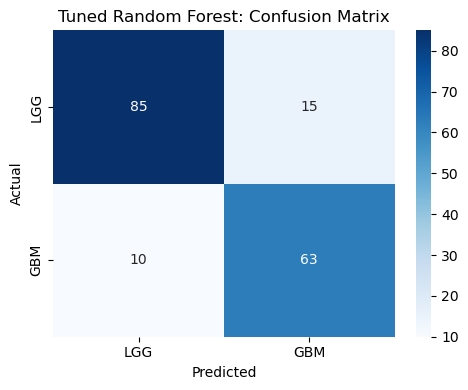

In [37]:
print('=' * 60)
print('CONFUSION MATRIX: TUNED RF')
print('=' * 60)

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG', 'GBM'],
            yticklabels=['LGG', 'GBM'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest: Confusion Matrix')
plt.tight_layout()
plt.savefig('cm_rf_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

### Permutation Feature Importance

The built-in `feature_importances_` in Random Forest uses mean decrease in impurity, which can overrate features that happen to have many possible split points. Permutation importance is more reliable because it shuffles each feature one at a time and measures how much accuracy drops as a result. If shuffling a feature barely changes anything, then it was not really helping the model and its apparent importance from the tree structure was misleading.

PERMUTATION FEATURE IMPORTANCE
         Feature  Importance Mean  Importance Std
            IDH1           0.1780          0.0261
Age_at_diagnosis           0.0538          0.0156
             CIC           0.0162          0.0122
            EGFR           0.0130          0.0141
          NOTCH1           0.0058          0.0026
           MUC16           0.0038          0.0038
            PTEN           0.0023          0.0064
             RB1           0.0003          0.0013
             NF1           0.0000          0.0000
          PIK3R1           0.0000          0.0000
            TP53           0.0000          0.0000
          PIK3CA           0.0000          0.0000
            BCOR           0.0000          0.0000
           CSMD3           0.0000          0.0000
         SMARCA4           0.0000          0.0000
          GRIN2A           0.0000          0.0000
            IDH2           0.0000          0.0000
            FAT4           0.0000          0.0000
          PDGFRA   

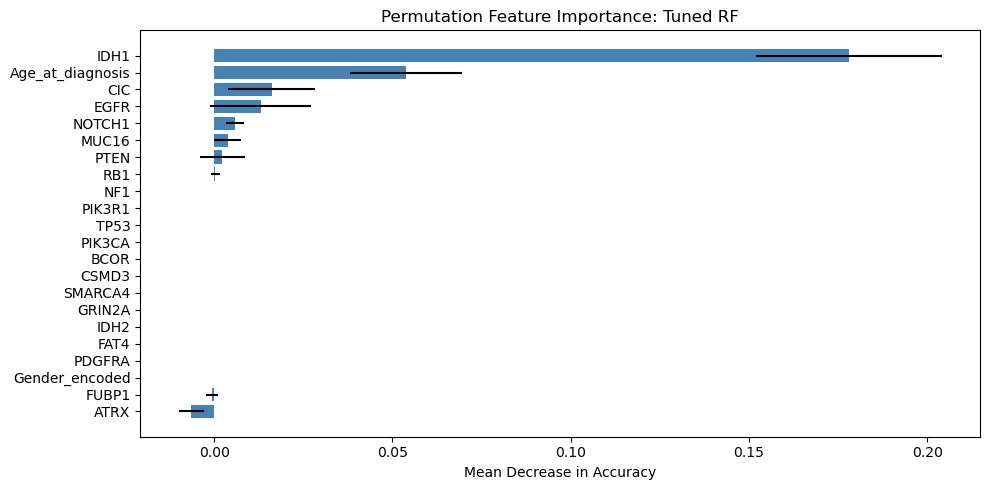

In [38]:
print('=' * 60)
print('PERMUTATION FEATURE IMPORTANCE')
print('=' * 60)

# permutation importance shuffles each feature one at a time and measures
# how much accuracy drops — more reliable than Gini importance from the tree
# because Gini can overrate features with many possible split points
# n_repeats=20 runs each shuffle 20 times so we get a mean and std per feature
# high mean + low std = reliably important; high std = unstable, treat with caution

perm_imp = permutation_importance(
    rf_tuned,
    X_test,      
    y_test,
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_imp.importances_mean.round(4),
    'Importance Std': perm_imp.importances_std.round(4)
}).sort_values('Importance Mean', ascending=False)

print(perm_df.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(perm_df['Feature'], perm_df['Importance Mean'],
         xerr=perm_df['Importance Std'], color='steelblue')
plt.xlabel('Mean Decrease in Accuracy')
plt.title('Permutation Feature Importance: Tuned RF')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('permutation_importance.png', dpi=300, bbox_inches='tight')
plt.show()

### Baseline RF vs Tuned RF

Comparing the baseline Random Forest against the tuned version on the same test set to check whether GridSearchCV actually made a meaningful difference, or whether the tuning just reshuffled the numbers without real improvement.

In [39]:
print('=' * 60)
print('BASELINE RF vs TUNED RF')
print('=' * 60)

cm_rf_base = confusion_matrix(y_test, y_pred_rf)
cm_rf_tune = confusion_matrix(y_test, y_pred_tuned)

def get_metrics(cm, y_true, y_pred, probs):
    # GBM=1, LGG=0 so GBM true positives sit at cm[1][1]
    gbm_tp = cm[1][1]
    gbm_fn = cm[1][0]
    lgg_tp = cm[0][0]
    lgg_fn = cm[0][1]
    return {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'GBM Sensitivity': round(gbm_tp / (gbm_tp + gbm_fn), 4),
        'Specificity': round(lgg_tp / (lgg_tp + lgg_fn), 4),
        'AUC': round(roc_auc_score(y_true, probs), 4)
    }

baseline_metrics = get_metrics(cm_rf_base, y_test, y_pred_rf, rf.predict_proba(X_test_scaled)[:, 1])
tuned_metrics = get_metrics(cm_rf_tune, y_test, y_pred_tuned, rf_tuned.predict_proba(X_test)[:, 1])

comparison = pd.DataFrame({
    'Baseline RF': baseline_metrics,
    'Tuned RF': tuned_metrics
})

print(comparison)

BASELINE RF vs TUNED RF
                 Baseline RF  Tuned RF
Accuracy              0.8208    0.8555
GBM Sensitivity       0.7808    0.8630
Specificity           0.8500    0.8500
AUC                   0.9091    0.9084


Tuning improved sensitivity from 0.78 to 0.86, meaning the tuned RF catches significantly more GBM cases than the baseline. Accuracy also went from 0.82 to 0.86. The improvement is real, but it only brings RF up to the level of SVM and Logistic Regression rather than beyond them. LR still wins on the metric combination that matters most clinically, with the highest sensitivity among deployable models (0.88) alongside the best accuracy and AUC.

## Decision Threshold Analysis

All the models above used the default 0.5 probability threshold to decide between GBM and LGG. In a clinical setting where missing a GBM is far worse than a false alarm, that default may not be the right choice. The table below tests the SVM at thresholds from 0.3 to 0.7.

Sensitivity stays flat at 0.8630 for thresholds 0.3 through 0.5 because the SVM's probability outputs are not clustered near the decision boundary. Most predictions sit well above or well below 0.5, so nudging the threshold within that range does not reclassify any patients.

Raising the threshold to 0.6 tightens specificity (0.81 to 0.84) without losing sensitivity, because it removes a few borderline LGG cases the default was letting through as GBM. Pushing to 0.7 starts to cost sensitivity, which is the tradeoff the clinical team would need to weigh. For this model, 0.6 is actually a better operating point than 0.5.

In [40]:
print('=' * 60)
print('DECISION THRESHOLD ANALYSIS: SVM')
print('=' * 60)

# SVM had the best baseline sensitivity so testing threshold shifts on it
# predict_proba[:, 1] gives GBM probability because GBM is class 1 now
svm_probs_gbm = svm.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

print(f'{"Threshold":<12} {"Sensitivity":<14} {"Specificity":<14} {"Accuracy":<12}')
print('-' * 52)

for t in thresholds:
    # if GBM probability >= threshold predict GBM (1) otherwise LGG (0)
    y_pred_t = np.where(svm_probs_gbm >= t, 1, 0)

    cm_t = confusion_matrix(y_test, y_pred_t)
    sens = cm_t[1][1] / (cm_t[1][1] + cm_t[1][0])  # GBM recall
    spec = cm_t[0][0] / (cm_t[0][0] + cm_t[0][1])  # LGG recall
    acc = accuracy_score(y_test, y_pred_t)
    print(f'{t:<12.1f} {sens:<14.4f} {spec:<14.4f} {acc:<12.4f}')

print()
print('Lower threshold = catches more GBM but increases false alarms.')
print('The right threshold depends on how the clinical team weighs missed cancers vs extra testing.')

DECISION THRESHOLD ANALYSIS: SVM
Threshold    Sensitivity    Specificity    Accuracy    
----------------------------------------------------
0.3          0.8630         0.8100         0.8324      
0.4          0.8630         0.8100         0.8324      
0.5          0.8630         0.8100         0.8324      
0.6          0.8630         0.8400         0.8497      
0.7          0.8356         0.8400         0.8382      

Lower threshold = catches more GBM but increases false alarms.
The right threshold depends on how the clinical team weighs missed cancers vs extra testing.


### Decision Threshold Analysis: Logistic Regression

Running the same threshold sweep on Logistic Regression since it is the recommended model. Unlike SVM where sensitivity was flat from 0.3 to 0.5, LR's probability outputs are more spread across the range, so threshold shifts produce more visible tradeoffs.

In [41]:
print('=' * 60)
print('DECISION THRESHOLD ANALYSIS: LOGISTIC REGRESSION')
print('=' * 60)

# LR is the recommended model so the threshold analysis should cover it too
# predict_proba[:, 1] gives GBM probability because GBM is class 1
lr_probs_gbm = lr.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

print(f'{"Threshold":<12} {"Sensitivity":<14} {"Specificity":<14} {"Accuracy":<12}')
print('-' * 52)

for t in thresholds:
    # predict GBM if probability >= threshold, otherwise LGG
    y_pred_t = np.where(lr_probs_gbm >= t, 1, 0)

    cm_t = confusion_matrix(y_test, y_pred_t)
    sens = cm_t[1][1] / (cm_t[1][1] + cm_t[1][0])  # GBM recall
    spec = cm_t[0][0] / (cm_t[0][0] + cm_t[0][1])  # LGG recall
    acc = accuracy_score(y_test, y_pred_t)
    print(f'{t:<12.1f} {sens:<14.4f} {spec:<14.4f} {acc:<12.4f}')

print()
print('At threshold 0.4, LR catches more GBM at the cost of more false positives.')
print('The optimal operating point depends on how the clinical team weights missed GBM vs unnecessary referrals.')

DECISION THRESHOLD ANALYSIS: LOGISTIC REGRESSION
Threshold    Sensitivity    Specificity    Accuracy    
----------------------------------------------------
0.3          0.9041         0.7900         0.8382      
0.4          0.8904         0.8200         0.8497      
0.5          0.8767         0.8300         0.8497      
0.6          0.8767         0.8500         0.8613      
0.7          0.7671         0.8600         0.8208      

At threshold 0.4, LR catches more GBM at the cost of more false positives.
The optimal operating point depends on how the clinical team weights missed GBM vs unnecessary referrals.


## Final Recommendation
Logistic Regression is the strongest all-round model here. It caught 64 out of 73 GBM cases in the test set, the highest sensitivity among the deployable models at 0.88, with the best accuracy at 0.85 and the highest AUC at 0.90. SVM comes close on sensitivity (0.86) but loses on accuracy and AUC. The tuned Random Forest also reaches 0.86 sensitivity with similar specificity, but LR gets there more simply and the decision logic can be explained directly to a clinical team without needing a statistics degree.
Gaussian Naive Bayes had the highest raw sensitivity at 0.90, but its specificity collapsed to 0.54 and overall accuracy dropped to 0.69. It flagged too many LGGs as GBM to be useful. This confirms that the independence assumption does not fit the data, since mutation features are known to co-occur (IDH1 with ATRX and TP53 in LGG astrocytomas for example). GNB is kept in the comparison as the probabilistic baseline, but it is not a candidate for deployment.
Tuning improved the Random Forest meaningfully, with sensitivity rising from 0.78 to 0.86 and accuracy from 0.82 to 0.86. That is a real improvement and it closes the gap with LR, but it does not beat it. The tuning step is worth keeping in the analysis because it shows that default hyperparameters leave performance on the table.
None of these models should go anywhere near a patient without prospective validation on an independent cohort first. TCGA is a curated research dataset from major academic centres and real-world diagnostic samples would differ in important ways. Referral bias means TCGA skews towards complex or ambiguous cases, the demographic mix is 89% white which limits generalisability to other populations, and tissue processing protocols vary between hospitals which could affect mutation calling. A prospective study on routine NHS neuropathology samples would be the minimum required before any deployment decision.
Full discussion of dataset limitations, demographic bias, and the validation pathway for clinical deployment is covered in the technical report.